# What does the LDA capture once the wheel is in it? — 6 wheel states, no split / no merge (wheel7)

The paper's mouse-weighted shrinkage LDA (`lda_shrinkage_core.MouseEmbedding`, shrinkage 0.5 as the saved embedding `mouse_LDA_5_bins_raw_shrink0.5_wmouse_360`) refitted on the syllable features **plus the wheel movement states** (3.4, as one-hot per bin; features from `wheel_lda_test.py`), then the two analyses of `fig_ld1`:
1. **syllable correlations**: per trial bin, the correlation across sessions between a state's occupancy and LD1 (permutation band), now including the wheel states;
2. **trial-metric correlations**: `LDA_behavior`'s session summaries (accuracy, bias, RT, elongation, trials, training time) against LD1;

and the other LD1 correlations of the paper:

3. **engagement** (`fig_engagement`): the 2-state GLM-HMM session measures (fraction engaged, engaged log ratio, state switches, switches at equal accuracy, P(stay), switches at K = 4, held-out gain of more states) against LD1;
4. **neural** (`fig_neural`): `lda1_neural_metrics.run_tests` -- firing rate, Fano factor and r_SC against LD1 (GLM slope with region and trial-count covariates, session permutation).

Everything is shown for the new LD1 and, side by side, the production LD1, so the question is what the wheel changes. `VARIANT` picks the wheel state set (`wheel8`: still, small, side × mid / high; `wheel10`: side × vigor).

In [1]:
import sys, pathlib, glob, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'trial_modes.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
for p in [PI, PI / 'learning_individuality', PI / '4_mice', PI / 'segmentation']:
    sys.path.insert(0, str(p))
import paper_style as ps
import lda_shrinkage_core as lsc
import wheel_lda_test as wlt
import wheel_movement_clusters as wmc
ps.use('paper', dpi=110); ps.use_paw_states('uniform')

VARIANT = 'wheel7'          # no split, no merge: one GMM, K = 6 (+ still); representation_learning/wheel_movements/nosplit_states.py
K_WHEEL = int(VARIANT[5:])
GROUPING = {7: None, 8: 'small_side_vigor', 10: 'side_vigor', 17: 'sided_both2', 21: None}[K_WHEEL]
SHRINKAGE = 0.5                  # as the saved production embedding
LDA_FILE = PI / 'clustering' / 'data_files' / 'mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026'
TRIAL_META = PI / 'data' / 'session_trial_meta_19-08-2026'
TRAINING_FILE = REPO / 'learning_prediction' / 'training_time_05-05-2026'
N_PERMS, SEED = 1000, 0
EPOCHS = ps.EPOCH_NAMES
import pickle
WM = (pickle.load(open(wmc.states_dir('proficient') + 'model_k7_nosplit.pkl', 'rb')) if K_WHEEL == 7
      else wmc.load_model('proficient', 21))
W_NAMES = wmc.state_names(WM, GROUPING)
W_COLORS = ['#BDBDBD'] + wmc.colours(WM, GROUPING)[1:]       # still drawn mid grey so its line is visible
assert len(W_NAMES) == K_WHEEL

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Embeddings: production LD1 reproduced, then refitted with the wheel

In [2]:
Xn, mouse = wlt.features(VARIANT)
Xb, mouse_b = wlt.features('base')
assert (Xn.index == Xb.index).all() and (mouse.values == mouse_b.values).all()
prod = pd.read_pickle(LDA_FILE).set_index('session').reindex(Xb.index)
sessions, mice = Xb.index.to_numpy(), mouse.to_numpy()

E_base = lsc.MouseEmbedding(Xb.to_numpy(float), mice, shrinkage=SHRINKAGE)
E_new = lsc.MouseEmbedding(Xn.to_numpy(float), mice, shrinkage=SHRINKAGE)
Zb, Zn = E_base.transform(Xb.to_numpy(float), 3), E_new.transform(Xn.to_numpy(float), 3)
P = prod[[0, 1, 2]].to_numpy(float)
r_repro = [pearsonr(Zb[:, i], P[:, i])[0] for i in range(3)]
print('refit on the production features vs the saved embedding, LD1-3: r =', np.round(r_repro, 4))

# orient each new axis like the production axis it correlates with most
R = np.array([[pearsonr(Zn[:, i], P[:, j])[0] for j in range(3)] for i in range(3)])
for i in range(3):
    Zn[:, i] *= np.sign(R[i, np.argmax(np.abs(R[i]))])
R = np.array([[pearsonr(Zn[:, i], P[:, j])[0] for j in range(3)] for i in range(3)])
mm = lambda Z: pd.DataFrame(Z).groupby(mice).mean().to_numpy()
Rm = np.array([[pearsonr(mm(Zn)[:, i], mm(P)[:, j])[0] for j in range(3)] for i in range(3)])
idx = [f'new LD{i + 1}' for i in range(3)]; cols = [f'production LD{j + 1}' for j in range(3)]
print(f'between-mouse share, production: {np.round(E_base.axis_share[:3], 3)};  with the wheel: {np.round(E_new.axis_share[:3], 3)}')
display(pd.concat({'sessions': pd.DataFrame(R, idx, cols), 'mouse means': pd.DataFrame(Rm, idx, cols)}, axis=1).round(3))
LD = pd.DataFrame({'session': sessions, 'mouse_name': mice, 'LD1_new': Zn[:, 0], 'LD2_new': Zn[:, 1], 'LD3_new': Zn[:, 2],
                   'LD1_prod': P[:, 0], 'LD2_prod': P[:, 1], 'LD3_prod': P[:, 2]})

refit on the production features vs the saved embedding, LD1-3: r = [1. 1. 1.]
between-mouse share, production: [0.136 0.099 0.085];  with the wheel: [0.118 0.098 0.078]


sessions                                  mouse means  \
        production LD1 production LD2 production LD3 production LD1   
new LD1          0.913         -0.113         -0.057          0.926   
new LD2          0.308          0.740          0.002          0.269   
new LD3         -0.302          0.548         -0.273         -0.189   

                                       
        production LD2 production LD3  
new LD1         -0.124         -0.058  
new LD2          0.784          0.011  
new LD3          0.542         -0.288

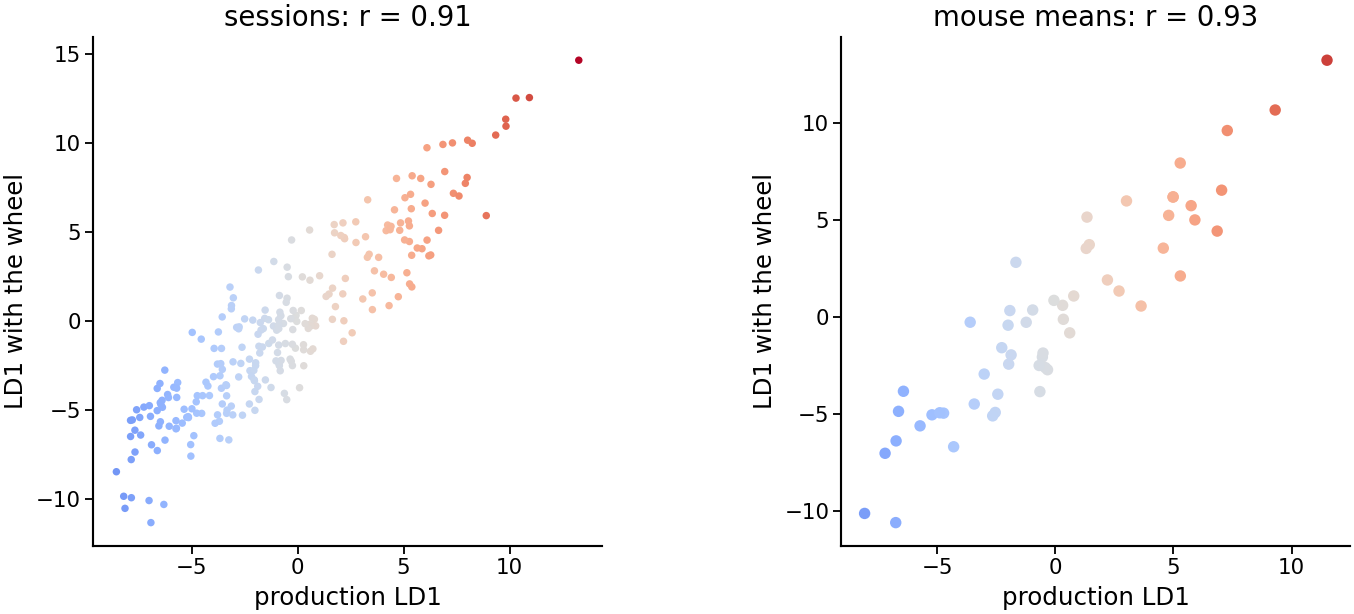

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(7, 3))
for ax, Z_, Pp, lab in [(axs[0], LD.LD1_new, LD.LD1_prod, 'sessions'),
                        (axs[1], LD.groupby('mouse_name').LD1_new.mean(), LD.groupby('mouse_name').LD1_prod.mean(), 'mouse means')]:
    ax.scatter(Pp, Z_, s=6 if lab == 'sessions' else 14, c=ps.LD1_CMAP(ps.ld1_norm(LD.LD1_prod.to_numpy())(np.asarray(Pp))), lw=0)
    ax.set(xlabel='production LD1', ylabel='LD1 with the wheel', title=f'{lab}: r = {pearsonr(Pp, Z_)[0]:.2f}')
    ax.set_box_aspect(1)
plt.tight_layout()

## 1. Syllable correlations along LD1 — including the wheel states

Per trial bin (4 epochs × 10), the correlation across the 260 sessions between a state's occupancy in that bin and LD1. Grey band = 95 % of the same correlation with LD1 permuted across sessions (envelope over the states in a panel); traces solid where they leave it. Top row: the LD1 refitted with the wheel; bottom: the production LD1 (fit without the wheel), to see whether wheel use already lined up with it.

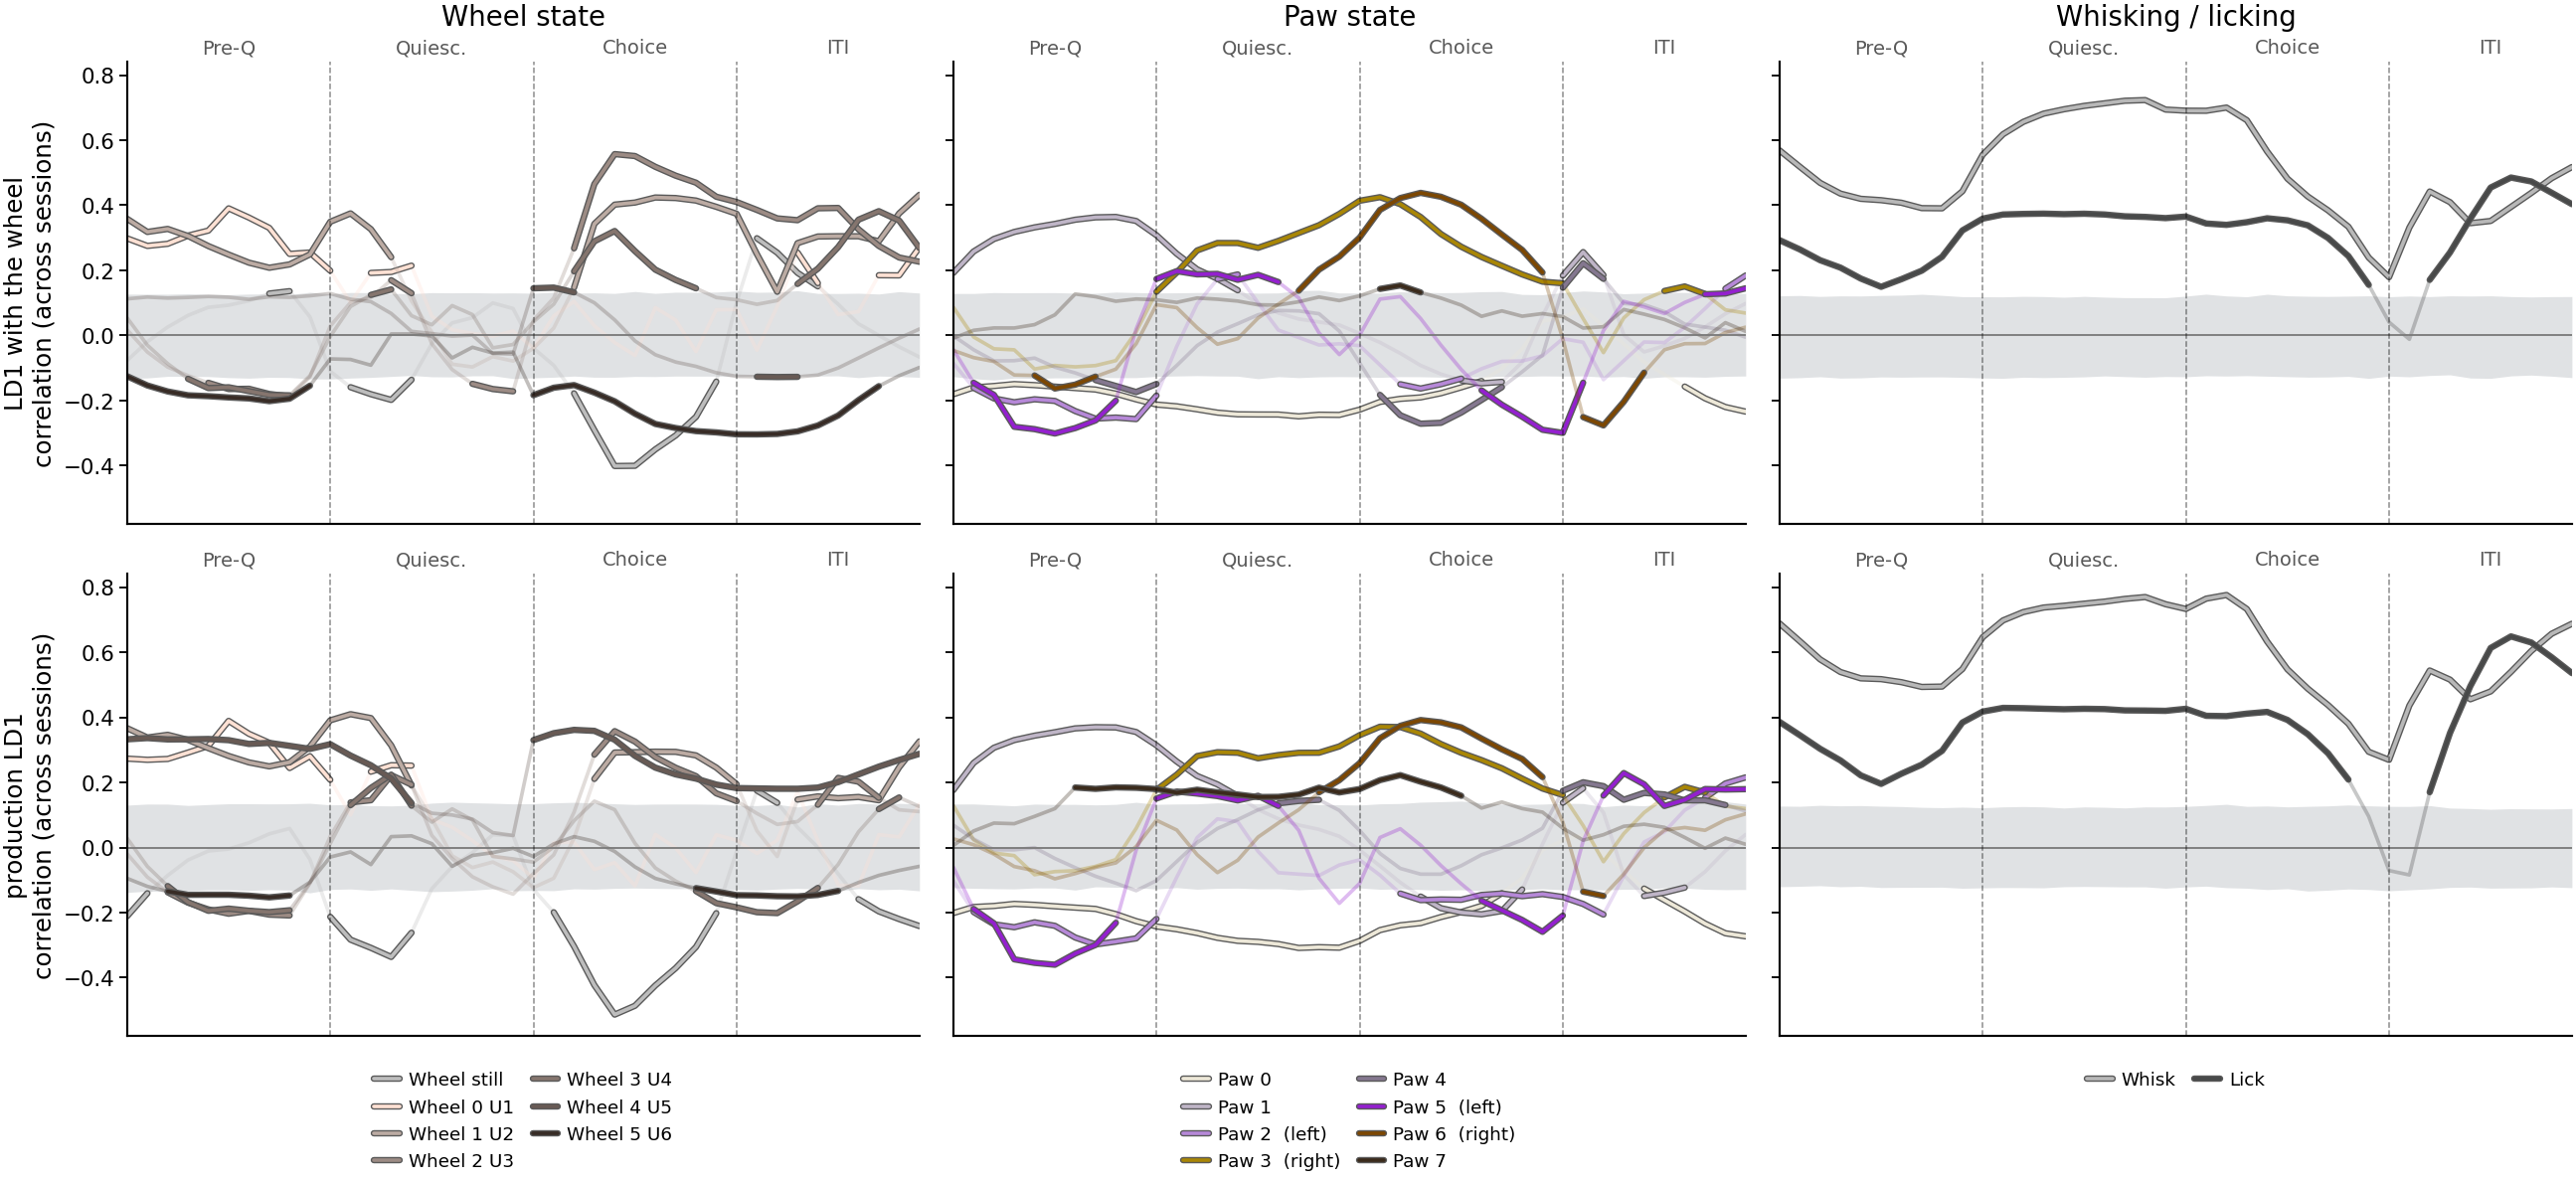

In [4]:
syl = pd.read_parquet(sorted(glob.glob(
    str(PI / 'data' / f'both_paws+wheelmov-sep_k8-{K_WHEEL}_own_lick-standard_proficient_8_k_10_bin_syllables_*')))[-1])
syl['session'] = syl['sample'].str[:36]
syl = syl[syl['session'].isin(sessions)]
tr = (syl.pivot(index=['mouse_name', 'session', 'sample'], columns='broader_label', values=['binned_sequence', 'wheel_binned_sequence'])
      .dropna().reset_index())
stack = lambda col: np.vstack([np.hstack(r) for r in tr[[(col, e) for e in EPOCHS]].to_numpy()]).astype(float)
codes, wheel = ps.paw_codes(stack('binned_sequence')), stack('wheel_binned_sequence')
paw, whisk, lick = ps.decode_syllables(codes)
OCC = np.stack([np.where(np.isnan(paw), np.nan, paw == k) for k in range(ps.N_PAW_STATES)] + [whisk, lick]
               + [np.where(np.isnan(wheel), np.nan, wheel == k) for k in range(K_WHEEL)], axis=-1)
sidx = tr[('session', '')].to_numpy()
with np.errstate(invalid='ignore'):
    SESS_OCC = np.stack([np.nanmean(OCC[sidx == s], axis=0) for s in sessions])     # (sessions, 40, 8 + 2 + K)
N_BINS = SESS_OCC.shape[1]
PAW_F, WL_F, WH_F = list(range(ps.N_PAW_STATES)), [8, 9], list(range(10, 10 + K_WHEEL))
LABEL = [ps.paw_label(k) for k in range(ps.N_PAW_STATES)] + ['Whisk', 'Lick'] + [f'Wheel {n}' for n in W_NAMES]
COLOR = list(ps.SYLLABLE_COLORS) + W_COLORS

def colwise_r(Mx, v):
    Mc = np.nan_to_num(Mx - np.nanmean(Mx, axis=0)); vc = v - v.mean()
    return (Mc.T @ vc) / (np.sqrt((Mc ** 2).sum(axis=0)) * np.sqrt((vc ** 2).sum()))
flat = SESS_OCC.reshape(len(sessions), -1)
STRUCT, BAND = {}, {}
rng = np.random.default_rng(SEED)
for key in ('LD1_new', 'LD1_prod'):
    v = LD[key].to_numpy()
    STRUCT[key] = colwise_r(flat, v).reshape(N_BINS, -1)
    null = np.stack([colwise_r(flat, rng.permutation(v)).reshape(N_BINS, -1) for _ in range(N_PERMS)])
    BAND[key] = np.nanpercentile(null, [2.5, 97.5], axis=0)
OUTLINE = [pe.Stroke(linewidth=plt.rcParams['lines.linewidth'] + 0.9, foreground='0.35'), pe.Normal()]

fig, axs = plt.subplots(2, 3, figsize=(12, 5.6), sharey=True)
for row, key in enumerate(('LD1_new', 'LD1_prod')):
    lo, hi = BAND[key]
    for ax, feats, title in zip(axs[row], [WH_F, PAW_F, WL_F], ['Wheel state', 'Paw state', 'Whisking / licking']):
        x = np.arange(N_BINS)
        ax.fill_between(x, lo[:, feats].min(1), hi[:, feats].max(1), color=ps.NULL_BAND, alpha=0.3, lw=0)
        for f in feats:
            y = STRUCT[key][:, f]
            ax.plot(x, y, color=COLOR[f], alpha=0.3)
            ax.plot(x, np.where((y >= lo[:, f]) & (y <= hi[:, f]), np.nan, y), color=COLOR[f], label=LABEL[f], path_effects=OUTLINE)
        ax.axhline(0, color=ps.NEUTRAL, lw=0.6); ps.epoch_lines(ax, N_BINS, label=True, names=ps.EPOCH_SHORT)
        ax.set(xlim=(0, N_BINS - 1), xticks=[])
        if row == 0: ax.set_title(title, pad=12)
        if row == 1: ax.legend(frameon=False, fontsize=6, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.05))
    axs[row, 0].set_ylabel(('LD1 with the wheel' if key == 'LD1_new' else 'production LD1') + '\ncorrelation (across sessions)')
plt.tight_layout()

In [5]:
# summary: how strongly each state's occupancy tracks LD1 (max |r| over bins), new vs production LD1
summ = pd.DataFrame({'state': LABEL,
                     'max|r| with the wheel LD1': np.nanmax(np.abs(STRUCT['LD1_new']), axis=0),
                     'max|r| production LD1': np.nanmax(np.abs(STRUCT['LD1_prod']), axis=0),
                     'bins outside the band (wheel LD1)': ((STRUCT['LD1_new'] < BAND['LD1_new'][0]) | (STRUCT['LD1_new'] > BAND['LD1_new'][1])).sum(0),
                     'bins outside the band (production LD1)': ((STRUCT['LD1_prod'] < BAND['LD1_prod'][0]) | (STRUCT['LD1_prod'] > BAND['LD1_prod'][1])).sum(0)})
summ.round(3)

,state,max|r| with the wheel LD1,max|r| production LD1,bins outside the band (wheel LD1),bins outside the band (production LD1)
0,Paw 0,0.248,0.309,31,34
1,Paw 1,0.364,0.370,21,26
2,Paw 2 (left),0.257,0.298,19,24
3,Paw 3 (right),0.425,0.371,24,24
4,Paw 4,0.271,0.200,14,13
5,Paw 5 (left),0.301,0.360,25,29
6,Paw 6 (right),0.438,0.391,21,14
7,Paw 7,0.154,0.222,3,21
8,Whisk,0.723,0.776,40,40
9,Lick,0.485,0.648,38,37


In [6]:
# wheel states only, per epoch: mean r over the epoch's bins and the strongest bin outside the permutation band (new LD1)
rows = []
for f in WH_F:
    for e, ep in enumerate(EPOCHS):
        b = slice(e * 10, (e + 1) * 10)
        r = STRUCT['LD1_new'][b, f]; lo, hi = BAND['LD1_new'][0][b, f], BAND['LD1_new'][1][b, f]
        out = (r < lo) | (r > hi)
        rows.append(dict(state=LABEL[f], epoch=ep, mean_r=np.nanmean(r), n_sig_bins=int(out.sum()),
                         peak_sig_r=r[out][np.argmax(np.abs(r[out]))] if out.any() else np.nan))
W_EPOCH = pd.DataFrame(rows)
W_EPOCH.pivot(index='state', columns='epoch', values=['mean_r', 'n_sig_bins', 'peak_sig_r']).reindex(columns=EPOCHS, level=1).round(2)

mean_r                             n_sig_bins             \
epoch       Pre-quiescence Quiescence Choice   ITI Pre-quiescence Quiescence   
state                                                                          
Wheel 0 U1            0.31       0.10   0.02  0.13           10.0        4.0   
Wheel 1 U2            0.27       0.11   0.29  0.31           10.0        4.0   
Wheel 2 U3           -0.12      -0.01   0.39  0.34            5.0        5.0   
Wheel 3 U4           -0.12       0.05   0.18  0.23            6.0        2.0   
Wheel 4 U5            0.12       0.03   0.02 -0.08            1.0        1.0   
Wheel 5 U6           -0.18      -0.04  -0.23 -0.23           10.0        0.0   
Wheel still           0.06      -0.05  -0.24  0.10            2.0        4.0   

                             peak_sig_r                          
epoch       Choice   ITI Pre-quiescence Quiescence Choice   ITI  
state                                                            
Wheel 0 U1     0.0   5.0           0.39       0.21    NaN  0.27  
Wheel 1 U2     8.0  10.0           0.36       0.38   0.42  0.43  
Wheel 2 U3     8.0  10.0          -0.19      -0.17   0.56  0.41  
Wheel 3 U4     7.0   7.0          -0.18       0.14   0.32  0.38  
Wheel 4 U5     3.0   3.0           0.12       0.13   0.15 -0.13  
Wheel 5 U6    10.0   8.0          -0.20        NaN  -0.30 -0.30  
Wheel still    8.0   4.0           0.14      -0.20  -0.40  0.30

## 2. Trial-metric correlations along LD1

`LDA_behavior`'s session summaries, computed exactly as in `fig_ld1` panel C (same trial file, same definitions, same exclusion of mice whose log training time is 0 or 1). Session-level Pearson r (training time: per mouse, mouse-mean LD1) and the stricter mouse-level test (mouse means); Benjamini–Hochberg FDR over the eight measures, separately per LD1 version.

In [7]:
tf = pd.read_parquet(TRIAL_META)
tt = pd.read_parquet(TRAINING_FILE); tt['log_training'] = np.log(tt['training_days'])
excluded = tt.loc[tt['log_training'].isin([0, 1]), 'mouse_name'].tolist()
tt = tt[~tt['mouse_name'].isin(excluded)]; tf = tf[~tf['mouse_name'].isin(excluded)].copy()
tf['choice'] = tf['choice'].map({'left': 0, 'right': 1, 'nan': np.nan})
tf['correct'] = (tf['feedback'] == 'correct').astype(int)
zc = tf[tf['contrast'] == 0].groupby(['session', 'block'])['choice'].mean().unstack('block')
bias_df = pd.DataFrame({'session': zc.index, 'bias': (zc[0.8] - zc[0.2]).values})
hc = tf[tf['contrast'] > 0].copy(); hc['expected_right'] = (hc['signed_contrast'] < 0).astype(int)
cb = hc.groupby('session').agg(choice_mean=('choice', 'mean'), expected_right_mean=('expected_right', 'mean')).reset_index()
cb['signed_choice_bias'] = cb['choice_mean'] - cb['expected_right_mean']; cb['choice_bias'] = cb['signed_choice_bias'].abs()
n_trials = tf.groupby('session')['choice'].count().rename('trial_count').reset_index()
acc = tf[tf['contrast'] > 0.5].groupby('session')['correct'].mean().rename('correct').reset_index()
ss = tf.groupby(['session', 'mouse_name']).agg(reaction=('reaction', 'median'), elongation=('elongation', 'median')).reset_index()
with np.errstate(invalid='ignore'):
    ss['log_reaction'], ss['log_elongation'] = np.log(ss['reaction']), np.log(ss['elongation'])
beh = (ss.merge(bias_df, on='session').merge(cb[['session', 'choice_bias', 'signed_choice_bias']], on='session').merge(acc, on='session')
         .merge(n_trials, on='session').merge(tt[['mouse_name', 'log_training']], on='mouse_name')
         .merge(LD, on=['session', 'mouse_name'])).replace([np.inf, -np.inf], np.nan)
C_VARS = [('correct', 'Accuracy'), ('choice_bias', 'Choice bias'), ('signed_choice_bias', 'Signed choice bias'),
          ('bias', 'Bias shift'), ('log_reaction', 'Reaction time'), ('log_elongation', 'Trial elongation'),
          ('trial_count', 'Trials completed'), ('log_training', 'Training time')]
rows = []
for key in ('LD1_new', 'LD1_prod'):
    bm = beh.groupby('mouse_name')[[key] + [v for v, _ in C_VARS if v != 'log_training']].mean()
    bm['log_training'] = beh.groupby('mouse_name')['log_training'].first()
    for v, name in C_VARS:
        d = (bm if v == 'log_training' else beh)[[key, v]].dropna()
        r, p = pearsonr(d[key], d[v])
        dm = bm[[key, v]].dropna(); rm, pm_ = pearsonr(dm[key], dm[v])
        rows.append(dict(LD1=key, measure=name, r=r, p=p, n=len(d), r_mice=rm, p_mice=pm_))
TS = pd.DataFrame(rows)
for key in ('LD1_new', 'LD1_prod'):
    m = TS.LD1 == key
    TS.loc[m, 'q'] = multipletests(TS.loc[m, 'p'], method='fdr_bh')[1]
    TS.loc[m, 'q_mice'] = multipletests(TS.loc[m, 'p_mice'], method='fdr_bh')[1]
TS.pivot(index='measure', columns='LD1', values=['r', 'q', 'r_mice', 'q_mice']).reindex([n for _, n in C_VARS]).round(3)

r                q           r_mice           q_mice  \
LD1                LD1_new LD1_prod LD1_new LD1_prod LD1_new LD1_prod LD1_new   
measure                                                                         
Accuracy             0.165    0.184   0.022    0.012   0.219    0.214   0.225   
Choice bias         -0.188   -0.224   0.010    0.002  -0.168   -0.192   0.359   
Signed choice bias   0.031    0.039   0.731    0.551   0.047    0.053   0.748   
Bias shift           0.020   -0.044   0.765    0.551   0.083    0.045   0.736   
Reaction time       -0.235   -0.346   0.002    0.000  -0.304   -0.435   0.102   
Trial elongation    -0.033    0.057   0.731    0.507   0.045    0.159   0.748   
Trials completed    -0.143   -0.063   0.045    0.507  -0.227   -0.152   0.225   
Training time       -0.395   -0.344   0.010    0.022  -0.395   -0.344   0.025   

                             
LD1                LD1_prod  
measure                      
Accuracy              0.322  
Choice bias           0.329  
Signed choice bias    0.748  
Bias shift            0.748  
Reaction time         0.008  
Trial elongation      0.363  
Trials completed      0.363  
Training time         0.044

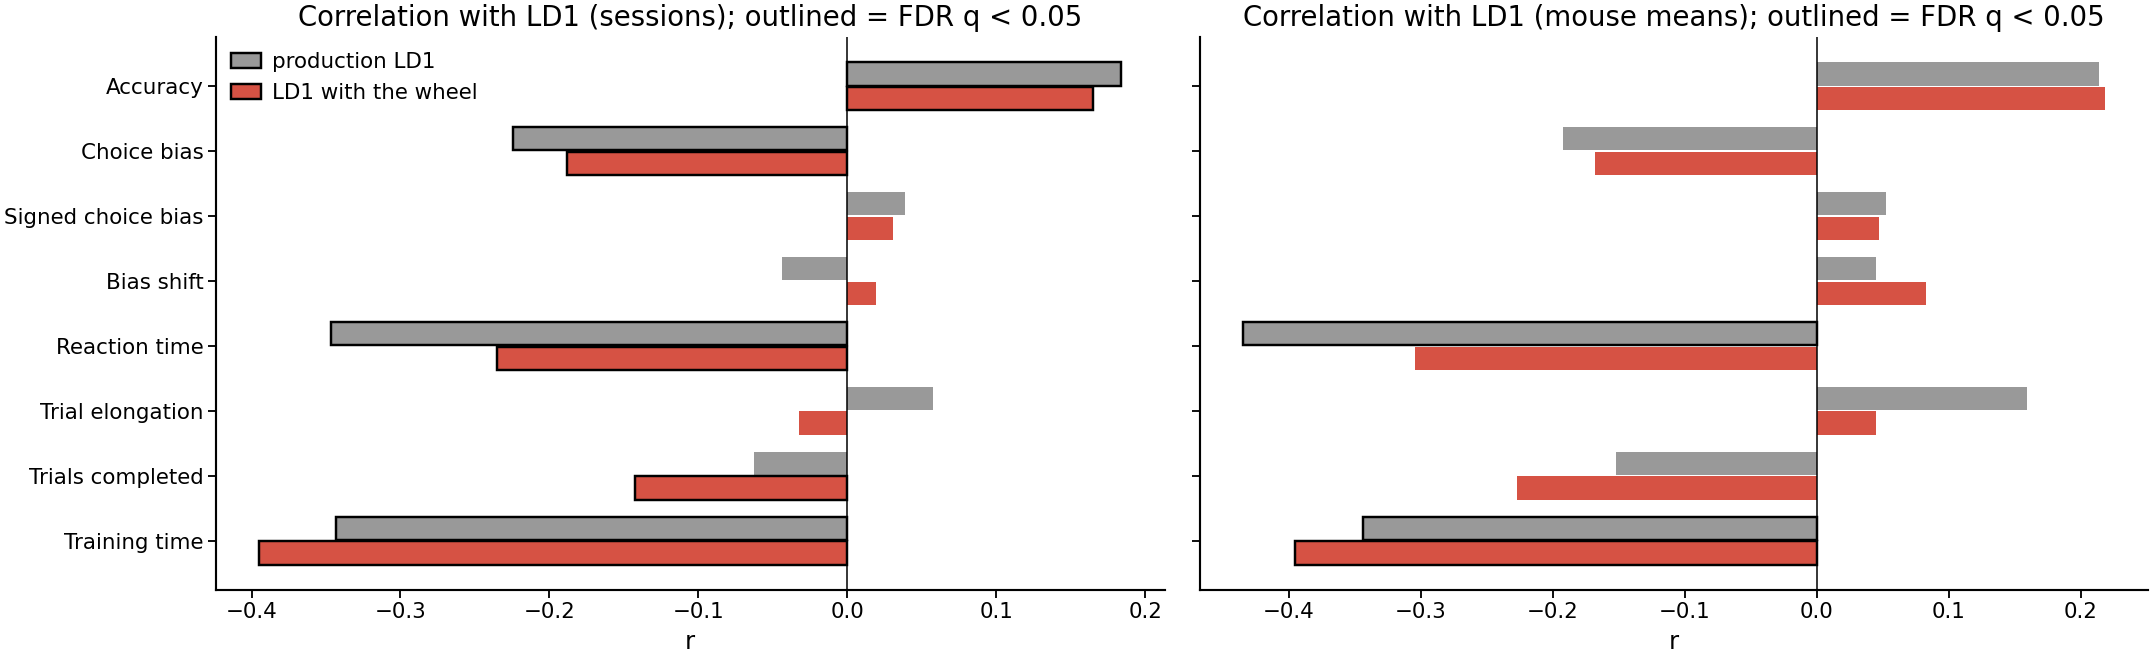

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
y = np.arange(len(C_VARS))
for ax, (rc, qc, title) in zip(axs, [('r', 'q', 'sessions'), ('r_mice', 'q_mice', 'mouse means')]):
    for j, (key, col, lab) in enumerate([('LD1_prod', '0.6', 'production LD1'), ('LD1_new', ps.LD1_CMAP(0.9), 'LD1 with the wheel')]):
        d = TS[TS.LD1 == key].set_index('measure').reindex([n for _, n in C_VARS])
        ax.barh(y + (j - 0.5) * 0.38, d[rc], height=0.36, color=col, label=lab,
                edgecolor=['k' if q < 0.05 else 'none' for q in d[qc]], lw=0.8)
    ax.axvline(0, color='k', lw=0.5); ax.set(title=f'Correlation with LD1 ({title}); outlined = FDR q < 0.05', xlabel='r')
axs[0].set_yticks(y, [n for _, n in C_VARS]); axs[0].invert_yaxis(); axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()

## 3. Engagement (GLM-HMM) measures along LD1

As `fig_engagement`: the K = 2 posteriors of `GLM-HMM/merged_behavioral_and_states.pqt`, each session cut to its first `N_TRUNC` (400) trials; engaged = P(engaged) ≥ 0.5. Pearson r with LD1 at the session level and with mouse means; 'switches | accuracy' is the partial correlation with easy-trial accuracy regressed out of both. FDR (BH) over the family, separately per LD1 version.

In [9]:
import statsmodels.formula.api as smf
GLM = PI / 'GLM-HMM'
N_TRUNC, I_K, H_STEPS = 400, 4, [(2, 3), (2, 4)]
gt = pd.read_parquet(GLM / 'merged_behavioral_and_states.pqt')
gt = gt[gt['eid'].isin(sessions)].copy()
gt['trial_id'] = gt.groupby('eid').cumcount()
gt['engaged'] = gt['p_state1'] >= 0.5
gt['correct'] = (gt['rewarded'] == 1).astype(int)
gt = gt[gt['trial_id'] < N_TRUNC]
def per_session(g):
    e = g['engaged'].to_numpy(); a, b = e[:-1], e[1:]
    return pd.Series({'frac_engaged': e.mean(), 'log_ratio': np.log(g['p_state1'].mean() / g['p_state2'].mean()),
                      'switches': (a != b).sum(),
                      'p_stay_eng': (a & b).sum() / a.sum() if a.sum() else np.nan,
                      'p_stay_dis': (~a & ~b).sum() / (~a).sum() if (~a).sum() else np.nan})
ENG = gt.groupby('eid')[['engaged', 'p_state1', 'p_state2']].apply(per_session)
ENG = ENG.join(gt[gt['signed_contrast'].abs() >= 0.25].groupby('eid')['correct'].mean().rename('p_easy'))
loso = pd.read_csv(GLM / 'k2_k3_pilot' / 'loso_k2_k3_k4_k5_wide.csv').set_index('held_out_session')
for a, b in H_STEPS:
    ENG = ENG.join((loso[f'bpt_K{b}'] - loso[f'bpt_K{a}']).rename(f'gain_{a}{b}'), how='left')
post = pd.read_parquet(GLM / 'k2_k3_pilot' / 'all_k_posteriors.parquet', filters=[('K', '==', I_K)],
                       columns=['eid', 'trial_idx', 'state', 'posterior'])
dom = post.sort_values('posterior').drop_duplicates(['eid', 'trial_idx'], keep='last').sort_values(['eid', 'trial_idx'])
dom = dom[dom['trial_idx'] < N_TRUNC]
ENG = ENG.join(dom.groupby('eid')['state'].agg(lambda x: int((np.diff(x.to_numpy()) != 0).sum())).rename(f'switches_k{I_K}'))
ENG = ENG.join(LD.set_index('session')[['mouse_name', 'LD1_new', 'LD1_prod']], how='inner')
print(f'{len(ENG)} sessions with GLM-HMM posteriors, {ENG.mouse_name.nunique()} mice')
E_TESTS = [('frac_engaged', 'Engaged trials', None), ('log_ratio', 'Engaged log ratio', None),
           ('switches', 'State switches', None), ('switches', 'Switches | accuracy', 'p_easy'),
           ('gain_23', 'Held-out gain K = 2 → 3', None), ('gain_24', 'Held-out gain K = 2 → 4', None),
           (f'switches_k{I_K}', f'Switches, K = {I_K}', None),
           ('p_stay_eng', 'Stay engaged', None), ('p_stay_dis', 'Stay disengaged', None)]
def eng_stats(frame, key):
    rows = []
    for col, name, cov in E_TESTS:
        d = frame[[key, col] + ([cov] if cov else [])].dropna().rename(columns={key: 'LD1'})
        if cov:
            rx = smf.ols(f'LD1 ~ {cov}', data=d).fit().resid; ry = smf.ols(f'{col} ~ {cov}', data=d).fit().resid
            r = pearsonr(rx, ry)[0]; p = smf.ols(f'{col} ~ LD1 + {cov}', data=d).fit().pvalues['LD1']
        else:
            r, p = pearsonr(d['LD1'], d[col])
        rows.append(dict(measure=name, r=r, p=p, n=len(d)))
    t = pd.DataFrame(rows); t['q'] = multipletests(t['p'], method='fdr_bh')[1]
    return t.set_index('measure')
ENG_M = ENG.groupby('mouse_name').mean(numeric_only=True)
ES = pd.concat({(lvl, key): eng_stats(fr, key) for lvl, fr in [('sessions', ENG), ('mice', ENG_M)]
                for key in ('LD1_new', 'LD1_prod')}, axis=1)
ES.round(3)

244 sessions with GLM-HMM posteriors, 56 mice


sessions                                          \
                         LD1_new                    LD1_prod               
                               r      p    n      q        r      p    n   
measure                                                                    
Engaged trials             0.021  0.740  244  0.740    0.037  0.564  244   
Engaged log ratio          0.214  0.001  244  0.001    0.239  0.000  244   
State switches            -0.328  0.000  244  0.000   -0.342  0.000  244   
Switches | accuracy       -0.231  0.000  244  0.001   -0.242  0.000  244   
Held-out gain K = 2 → 3   -0.066  0.318  231  0.357   -0.090  0.173  231   
Held-out gain K = 2 → 4   -0.111  0.091  231  0.117   -0.150  0.022  231   
Switches, K = 4           -0.247  0.000  231  0.000   -0.261  0.000  231   
Stay engaged               0.295  0.000  244  0.000    0.317  0.000  244   
Stay disengaged            0.178  0.007  228  0.011    0.168  0.011  228   

                                  mice                                        \
                               LD1_new                   LD1_prod              
                             q       r      p   n      q        r      p   n   
measure                                                                        
Engaged trials           0.564   0.037  0.787  56  0.787    0.004  0.976  56   
Engaged log ratio        0.000   0.270  0.044  56  0.097    0.248  0.065  56   
State switches           0.000  -0.420  0.001  56  0.008   -0.414  0.002  56   
Switches | accuracy      0.000  -0.335  0.013  56  0.038   -0.330  0.014  56   
Held-out gain K = 2 → 3  0.195  -0.139  0.324  52  0.365   -0.152  0.283  52   
Held-out gain K = 2 → 4  0.029  -0.186  0.188  52  0.241   -0.229  0.102  52   
Switches, K = 4          0.000  -0.269  0.054  52  0.097   -0.274  0.049  52   
Stay engaged             0.000   0.409  0.002  56  0.008    0.397  0.002  56   
Stay disengaged          0.017   0.194  0.151  56  0.227    0.223  0.098  56   

                                
                                
                             q  
measure                         
Engaged trials           0.976  
Engaged log ratio        0.118  
State switches           0.011  
Switches | accuracy      0.042  
Held-out gain K = 2 → 3  0.318  
Held-out gain K = 2 → 4  0.131  
Switches, K = 4          0.111  
Stay engaged             0.011  
Stay disengaged          0.131

/tmp/ipykernel_42327/4019069966.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  d = ES[(lvl, key)].reindex(names)


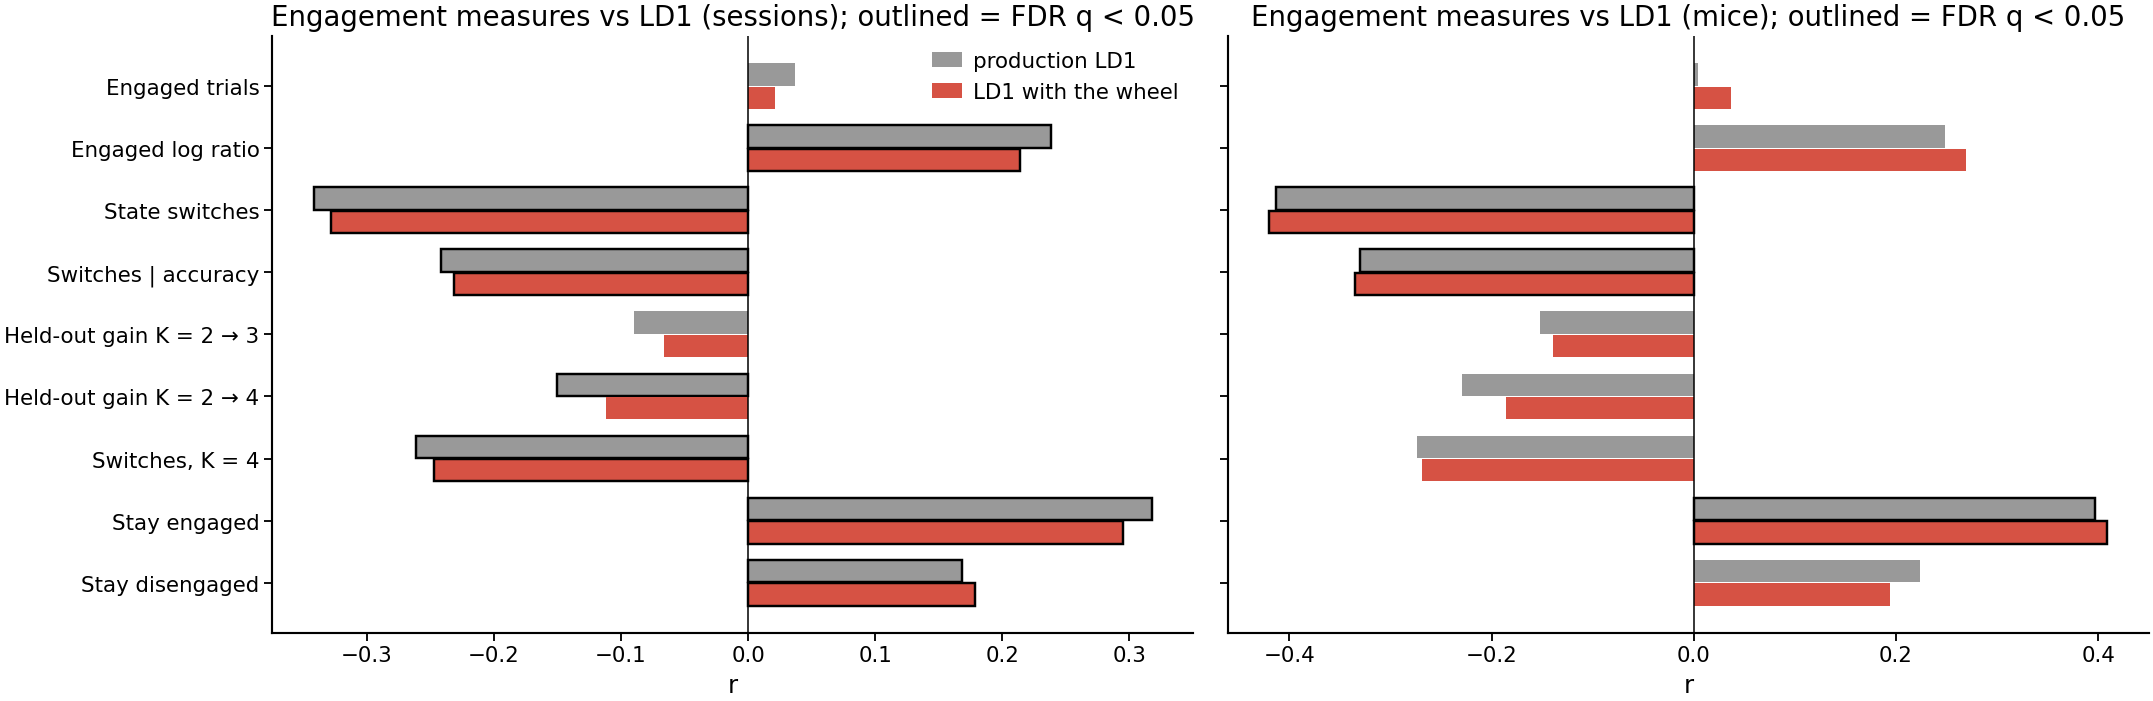

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
names = [n for _, n, _ in E_TESTS]; y = np.arange(len(names))
for ax, lvl in zip(axs, ['sessions', 'mice']):
    for j, (key, col, lab) in enumerate([('LD1_prod', '0.6', 'production LD1'), ('LD1_new', ps.LD1_CMAP(0.9), 'LD1 with the wheel')]):
        d = ES[(lvl, key)].reindex(names)
        ax.barh(y + (j - 0.5) * 0.38, d['r'], height=0.36, color=col, label=lab,
                edgecolor=['k' if q < 0.05 else 'none' for q in d['q']], lw=0.8)
    ax.axvline(0, color='k', lw=0.5); ax.set(title=f'Engagement measures vs LD1 ({lvl}); outlined = FDR q < 0.05', xlabel='r')
axs[0].set_yticks(y, names); axs[0].invert_yaxis(); axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()

## 4. Neural correlates along LD1

`fig_neural`'s tests unchanged: its QC settings, the cached metric tables, `apply_cohort(..., 'common')`, `run_tests` (GLM slope of LD1 with region and trial-count covariates; session-level permutation, 2000; FDR within each metric), response-onset tests left out as in the figure. Run twice, with the production LD1 and with the LD1 refitted with the wheel, both mapped onto the tables by session; neural sessions outside the 260 LDA sessions have no LD1 and drop out of both.

In [11]:
sys.path.insert(0, str(PI / 'neural'))
import lda1_neural_metrics as nm
import behaviour_models as bm
bm._numpy2_pickles()
cfg = nm.default_config()
cfg.update(MIN_FR_HZ=1.0, FR_FLOOR_REQUIRE='both', FR_FLOOR_SOURCE='session', UNIFORM_FR_FLOOR=True,
           MIN_PRESENCE_RATIO=0.90, MIN_NEURONS=15, MIN_NEURONS_RSC=None, LD1_SOURCE='current')
tables = nm.apply_cohort(nm.load_tables(cfg=cfg, verbose=False), cfg, 'common', verbose=False)
maps = {k: dict(zip(LD['session'], LD[k])) for k in ('LD1_new', 'LD1_prod')}
for k, t in tables.items():
    if isinstance(t, pd.DataFrame) and 'session' in t.columns:
        for c, m in maps.items():
            t[c] = t['session'].map(m)
def neural_tests(pred):
    res = nm.run_tests(tables, cfg, predictor=pred, verbose=False)
    res = res[res['test'] != 'Response onset'].copy()
    res['q_fdr_metric'] = res.groupby('metric')['p_perm'].transform(lambda p: multipletests(p, method='fdr_bh')[1])
    return res
NR = {k: neural_tests(k) for k in ('LD1_prod', 'LD1_new')}
cols = [c for c in ['metric', 'test', 'n_sessions', 'slope', 'r_partial', 'p_perm', 'q_fdr_metric'] if c in NR['LD1_prod'].columns]
NEU = NR['LD1_prod'][cols].merge(NR['LD1_new'][cols], on=['metric', 'test'], suffixes=(' (production)', ' (with wheel)'))
NEU.round(4)

,metric,test,n_sessions (production),slope (production),r_partial (production),p_perm (production),q_fdr_metric (production),n_sessions (with wheel),slope (with wheel),r_partial (with wheel),p_perm (with wheel),q_fdr_metric (with wheel)
0,Firing rate,Baseline,204,0.0136,0.0393,0.0450,0.1350,204,0.0137,0.0434,0.0290,0.0870
1,Firing rate,Post-stimulus,204,0.0037,0.0112,0.5185,0.5185,204,0.0031,0.0103,0.5525,0.5525
2,Firing rate,Response magnitude,204,0.0374,0.0132,0.2555,0.3833,204,0.0344,0.0133,0.2595,0.3893
3,Fano factor,Baseline,204,-0.0037,-0.0251,0.2135,0.2135,204,-0.0027,-0.0197,0.3490,0.3490
4,Fano factor,Post-stimulus,204,-0.0147,-0.0921,0.0000,0.0000,204,-0.0124,-0.0845,0.0005,0.0008
5,Fano factor,Response magnitude,204,-0.0237,-0.0928,0.0000,0.0000,204,-0.0222,-0.0948,0.0000,0.0000
6,Noise correlation,Baseline,203,-0.0007,-0.1585,0.0140,0.0140,203,-0.0007,-0.1703,0.0065,0.0098
7,Noise correlation,Post-stimulus,203,-0.0011,-0.2233,0.0005,0.0015,203,-0.0010,-0.2322,0.0000,0.0000
8,Noise correlation,Response magnitude,203,-0.0003,-0.1412,0.0130,0.0140,203,-0.0003,-0.1353,0.0140,0.0140
